In [1]:
import pandas as pd

# Charger le jeu de données
df = pd.read_csv('netflix_titles.csv')

# Afficher les 5 premières lignes
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
# 1. Vérifier la structure et les types de données
df.info()

# 2. Compter le nombre de valeurs manquantes par colonne
print("\n--- Valeurs manquantes ---")
print(df.isnull().sum())

# 3. Compter le nombre de lignes en double
print(f"\n--- Doublons ---")
print(f"Nombre de lignes en double : {df.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

--- Valeurs manquantes ---
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in     

In [3]:
# 1. Supprimer les doublons (s'il y en a)
df = df.drop_duplicates()

# 2. Remplacer les valeurs manquantes dans les colonnes de texte par 'Inconnu' ou non noté
df['director'] = df['director'].fillna('Inconnu')
df['cast'] = df['cast'].fillna('Inconnu')
df['country'] = df['country'].fillna('Inconnu')
df['rating'] = df['rating'].fillna('Non classé')

# 3. Supprimer les lignes où des informations critiques comme 'date_added' ou 'duration' manquent (le cas échéant)
df = df.dropna(subset=['date_added', 'duration'])

# 4. Nettoyer les espaces superflus dans les colonnes textuelles
df['title'] = df['title'].str.strip()
df['type'] = df['type'].str.strip()

print("Nettoyage des valeurs manquantes terminé avec succès !")

Nettoyage des valeurs manquantes terminé avec succès !


In [4]:
# 1. Convertir 'date_added' au format date (datetime)
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

# 2. Extraire l'année et le mois d'ajout pour de futures analyses
df['added_year'] = df['date_added'].dt.year
df['added_month'] = df['date_added'].dt.month

# 3. Convertir la colonne 'type' en type catégoriel
df['type'] = df['type'].astype('category')

# 4. Sauvegarder le dataset nettoyé dans un nouveau fichier CSV
df.to_csv('netflix_cleaned.csv', index=False)

print("Félicitations ! La Tâche 1 est terminée. Le fichier 'netflix_cleaned.csv' a été sauvegardé avec succès.")

Félicitations ! La Tâche 1 est terminée. Le fichier 'netflix_cleaned.csv' a été sauvegardé avec succès.


--- Statistiques descriptives ---
       show_id   type         title director     cast        country  \
count     8794   8794          8794     8794     8794           8794   
unique    8794      2          8793     4528     7682            749   
top      s8807  Movie  Consequences  Inconnu  Inconnu  United States   
freq         1   6128             2     2624      825           2809   
mean       NaN    NaN           NaN      NaN      NaN            NaN   
std        NaN    NaN           NaN      NaN      NaN            NaN   
min        NaN    NaN           NaN      NaN      NaN            NaN   
25%        NaN    NaN           NaN      NaN      NaN            NaN   
50%        NaN    NaN           NaN      NaN      NaN            NaN   
75%        NaN    NaN           NaN      NaN      NaN            NaN   
max        NaN    NaN           NaN      NaN      NaN            NaN   

        date_added  release_year rating  duration  \
count         8794   8794.000000   8794      879

/tmp/ipykernel_668/3755520286.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set2')


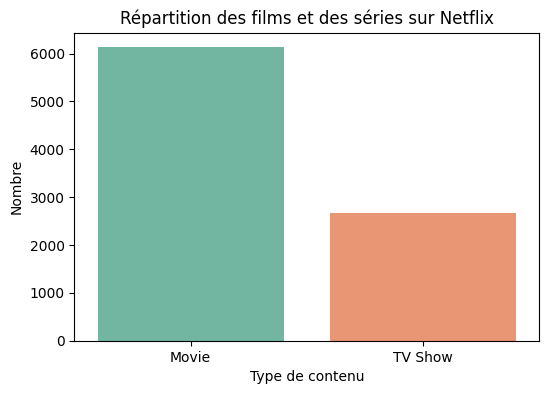

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le dataset nettoyé
df = pd.read_csv('netflix_cleaned.csv')

# 1. Analyser les statistiques descriptives de base
print("--- Statistiques descriptives ---")
print(df.describe(include='all'))

# 2. Étudier la distribution par type (Films vs Séries TV)
print("\n--- Distribution par type ---")
type_counts = df['type'].value_counts()
print(type_counts)

# Visualisation de la répartition par type
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='type', palette='Set2')
plt.title('Répartition des films et des séries sur Netflix')
plt.xlabel('Type de contenu')
plt.ylabel('Nombre')
plt.show()

--- Top 5 des pays producteurs ---
country
United States     2809
India              972
Inconnu            830
United Kingdom     418
Japan              244
Name: count, dtype: int64

--- Top 5 des catégories de contenu ---
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Name: count, dtype: int64


/tmp/ipykernel_668/1538758217.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='Blues_r')


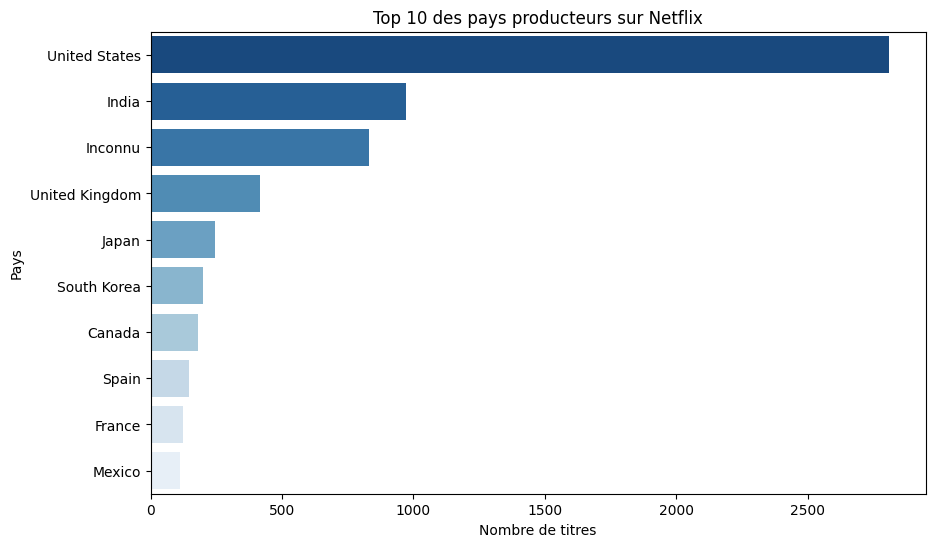

In [6]:
# 3. Identifier les principaux pays et catégories
print("--- Top 5 des pays producteurs ---")
print(df['country'].value_counts().head(5))

print("\n--- Top 5 des catégories de contenu ---")
print(df['listed_in'].value_counts().head(5))

# 4. Visualisation des 10 principaux pays producteurs de contenu
plt.figure(figsize=(10, 6))
top_countries = df['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='Blues_r')
plt.title('Top 10 des pays producteurs sur Netflix')
plt.xlabel('Nombre de titres')
plt.ylabel('Pays')
plt.show()

In [7]:
# 5. Résumé des insights clés de l'EDA
print("--- Résumé des insights de l'EDA ---")
print(f"Nombre total de titres analysés : {len(df)}")
print("\nPourcentage par type :")
print(df['type'].value_counts(normalize=True) * 100)
print(f"\nPays le plus producteur : {df['country'].mode()[0]}")
print(f"Année avec le plus de sorties : {df['release_year'].mode()[0]}")

--- Résumé des insights de l'EDA ---
Nombre total de titres analysés : 8794

Pourcentage par type :
type
Movie      69.683875
TV Show    30.316125
Name: proportion, dtype: float64

Pays le plus producteur : United States
Année avec le plus de sorties : 2018


In [8]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Charger le dataset nettoyé
df = pd.read_csv('netflix_cleaned.csv')

# Sélectionner les colonnes pertinentes pour la recommandation (titre et description/catégories)
# Remplir les valeurs nulles éventuelles par du texte vide
df['description'] = df['description'].fillna('')
df['listed_in'] = df['listed_in'].fillna('')

# Créer une colonne combinée 'soup' qui regroupe les mots-clés importants pour la recommandation
df['combined_features'] = df['listed_in'] + ' ' + df['description'] + ' ' + df['director']

# 2. Prétraitement du texte avec TF-IDF (pour convertir le texte en matrices numériques)
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

print(f"Forme de la matrice TF-IDF : {tfidf_matrix.shape}")
print("Étape 1 et 2 terminées avec succès !")


Forme de la matrice TF-IDF : (8794, 23907)
Étape 1 et 2 terminées avec succès !


In [9]:
# 3. Calculer la similarité cosinus entre les contenus
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Créer une correspondance inversée entre les titres et les indices du DataFrame
df = df.reset_index(drop=True)
indices = pd.Series(df.index, index=df['title']).drop_duplicates()

# 4. Fonction pour générer des recommandations de films/séries similaires
def get_recommendations(title, cosine_sim=cosine_sim):
    # Vérifier si le titre existe dans le dataset
    if title not in indices:
        return f"Le titre '{title}' n'est pas dans le dataset."

    # Obtenir l'index du film correspondant au titre
    idx = indices[title]

    # Obtenir les scores de similarité pour tous les titres
    sim_scores = list(enumerate(cosine_sim[idx]))

    # Trier les films selon les scores de similarité (du plus similaire au moins similaire)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Récupérer les indices des 10 films les plus similaires (en ignorant le film lui-même à l'indice 0)
    sim_scores = sim_scores[1:11]
    movie_indices = [i[0] for i in sim_scores]

    # Retourner les titres recommandés
    return df['title'].iloc[movie_indices]

# Test du système de recommandation avec un titre du dataset (par exemple, le premier titre)
sample_title = df['title'].iloc[0]
print(f"--- Recommandations pour : '{sample_title}' ---")
print(get_recommendations(sample_title))


--- Recommandations pour : 'Dick Johnson Is Dead' ---
3717                              Triple Threat
6548                                   Daffedar
5233    The Death and Life of Marsha P. Johnson
4877                                   End Game
829                            Dog Gone Trouble
7900                                   S.W.A.T.
2455                                 The Stolen
4033                                    Juanita
2083                       The Debt Collector 2
4698          To All the Boys I’ve Loved Before
Name: title, dtype: object


In [10]:
# 5. Évaluer rapidement la qualité en affichant les catégories et descriptions correspondantes
def evaluate_recommendations(title):
    print(f"Recommandations basées sur '{title}' (Catégorie : {df[df['title'] == title]['listed_in'].values[0]}) :\n")
    recs = get_recommendations(title)
    for rec in recs:
        rec_category = df[df['title'] == rec]['listed_in'].values[0]
        print(f"- {rec} | Catégorie : {rec_category}")

# Test de l'évaluation
evaluate_recommendations(sample_title)
print("\nÉtape 5 terminée ! Tâche 3 complétée avec succès.")


Recommandations basées sur 'Dick Johnson Is Dead' (Catégorie : Documentaries) :

- Triple Threat | Catégorie : Action & Adventure, International Movies
- Daffedar | Catégorie : Dramas, International Movies
- The Death and Life of Marsha P. Johnson | Catégorie : Documentaries, LGBTQ Movies
- End Game | Catégorie : Documentaries
- Dog Gone Trouble | Catégorie : Children & Family Movies, Comedies
- S.W.A.T. | Catégorie : Action & Adventure
- The Stolen | Catégorie : Dramas
- Juanita | Catégorie : Dramas, Independent Movies, Romantic Movies
- The Debt Collector 2 | Catégorie : Action & Adventure
- To All the Boys I’ve Loved Before | Catégorie : Comedies, International Movies, Romantic Movies

Étape 5 terminée ! Tâche 3 complétée avec succès.


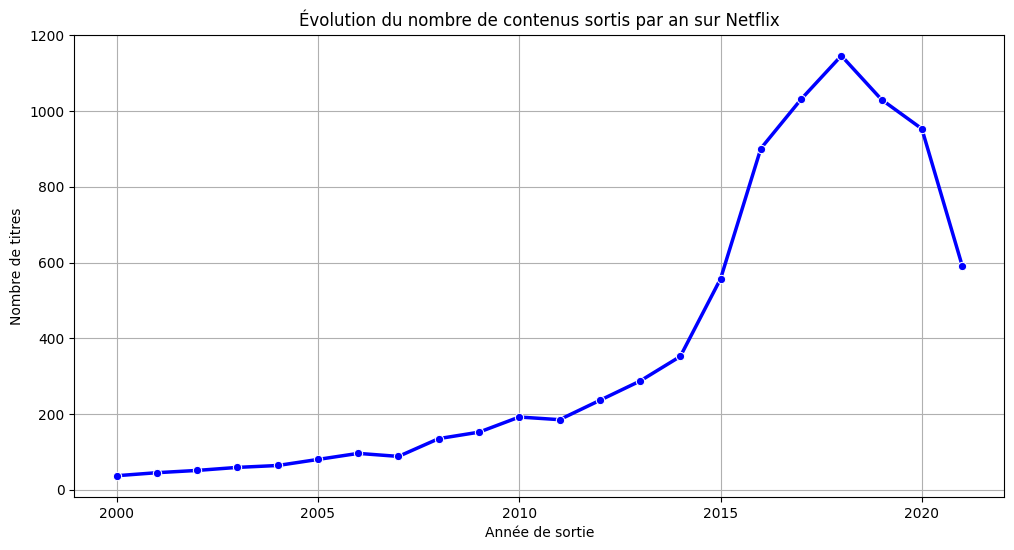

Étapes 1 et 2 terminées avec succès !


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Charger le dataset nettoyé
df = pd.read_csv('netflix_cleaned.csv')

# Préparer les données par année de sortie (release_year)
yearly_trend = df['release_year'].value_counts().sort_index()

# Filtrer pour garder les années récentes (par exemple à partir de l'an 2000 pour avoir une tendance claire)
yearly_trend = yearly_trend[yearly_trend.index >= 2000]

# 2. Analyser et visualiser les tendances annuelles du contenu
plt.figure(figsize=(12, 6))
sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='b', linewidth=2.5)
plt.title('Évolution du nombre de contenus sortis par an sur Netflix')
plt.xlabel('Année de sortie')
plt.ylabel('Nombre de titres')
plt.grid(True)
plt.show()

print("Étapes 1 et 2 terminées avec succès !")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


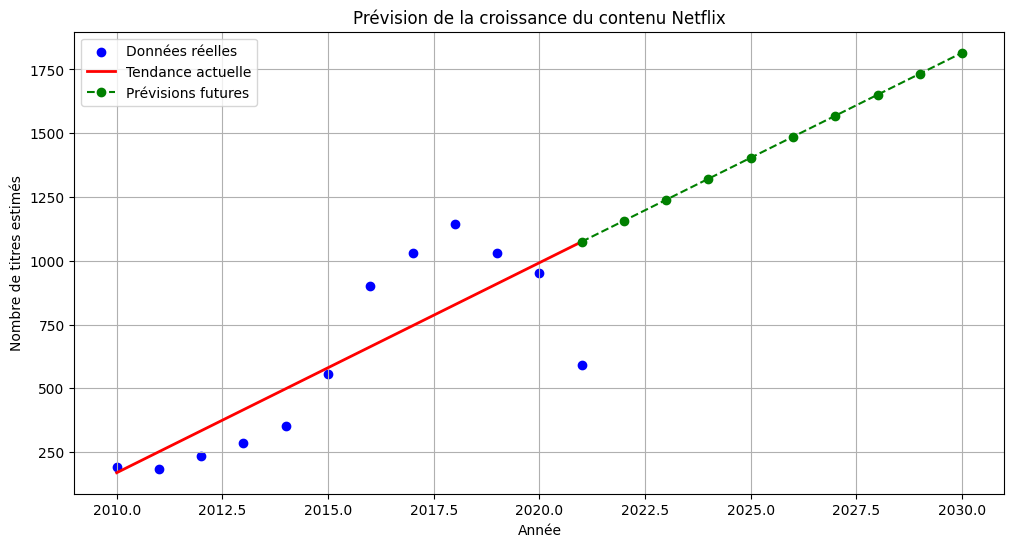

Étapes 3 et 4 terminées avec succès !


In [12]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Préparer les données pour le modèle (à partir de l'année 2010 pour capturer la croissance moderne)
df_trend = df[df['release_year'] >= 2010].groupby('release_year').size().reset_index(name='count')

X = df_trend[['release_year']] # Variable indépendante (Année)
y = df_trend['count']          # Variable dépendante (Nombre de titres)

# 3. Construire et entraîner le modèle de prévision
model = LinearRegression()
model.fit(X, y)

# Générer des prédictions pour les années futures (par exemple jusqu'en 2030)
future_years = np.array(range(2021, 2031)).reshape(-1, 1)
future_predictions = model.predict(future_years)

# 4. Visualiser les prédictions futures
plt.figure(figsize=(12, 6))
plt.scatter(X, y, color='blue', label='Données réelles')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Tendance actuelle')
plt.plot(future_years, future_predictions, color='green', linestyle='--', marker='o', label='Prévisions futures')
plt.title('Prévision de la croissance du contenu Netflix')
plt.xlabel('Année')
plt.ylabel('Nombre de titres estimés')
plt.legend()
plt.grid(True)
plt.show()

print("Étapes 3 et 4 terminées avec succès !")

In [13]:
# 5. Afficher les prédictions chiffrées pour les prochaines années
print("--- Prévisions chiffrées du contenu Netflix ---")
for year, pred in zip(future_years.flatten(), future_predictions):
    print(f"Année {year} : ~{int(pred)} titres prévus")

print("\nTâche 4 complétée avec succès !")

--- Prévisions chiffrées du contenu Netflix ---
Année 2021 : ~1074 titres prévus
Année 2022 : ~1156 titres prévus
Année 2023 : ~1239 titres prévus
Année 2024 : ~1321 titres prévus
Année 2025 : ~1403 titres prévus
Année 2026 : ~1486 titres prévus
Année 2027 : ~1568 titres prévus
Année 2028 : ~1650 titres prévus
Année 2029 : ~1733 titres prévus
Année 2030 : ~1815 titres prévus

Tâche 4 complétée avec succès !
